## Generating more data with SMOTE (oversampling)

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from imblearn.over_sampling import SMOTE, ADASYN

# load data
df = pd.read_csv("../../lifestyle_sustainability_data.csv")

# to simplify this example, let's filter only some of the variables
df = df[['Age', 'HomeSize', 'EnvironmentalAwareness', 'MonthlyElectricityConsumption', 'MonthlyWaterConsumption', 'Rating']]

<Axes: xlabel='Rating', ylabel='Count'>

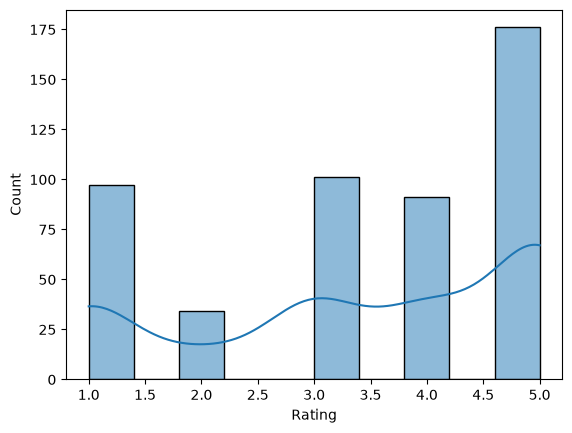

In [2]:
sns.histplot(data=df, x="Rating", kde=True)

## USE SMOTE TO GENERATE MISSING GAPS IN THE DATA

In [3]:
df['Rating'].value_counts().sort_index()

Rating
1     97
2     34
3    101
4     91
5    176
Name: count, dtype: int64

In [4]:
target = "Rating"

X = df.drop(target, axis=1)
y = df[target]

# define sampling strategy
# NOTE! this is oversampling, you can go over the original limit
# because you are generating more data
strategy = {
    1: 200,
    2: 300,
    3: 325,
    4: 300,
    5: 200,
}


# even if you go overboard with the generated data
# the statistics/correlations are still surprisingly close to orginal
# strategy = {
#     1: 1000,
#     2: 1000,
#     3: 1000,
#     4: 1000,
#     5: 1000,
# }

# use SMOTE with default settings (often enough)
# model = SMOTE()
model = SMOTE(sampling_strategy=strategy, random_state=123)

# ADASYN is an alternative to SMOTE, but is often a bit trickier to
# use with custom sampling strategies, you can "auto" though
# model = ADASYN(sampling_strategy="auto", random_state=123)

X_resampled, y_resampled = model.fit_resample(X, y)

# reconstruct the dataframe
df_resampled = pd.DataFrame(X_resampled, columns=X.columns)
df_resampled[target] = y_resampled

<Axes: xlabel='Rating', ylabel='Count'>

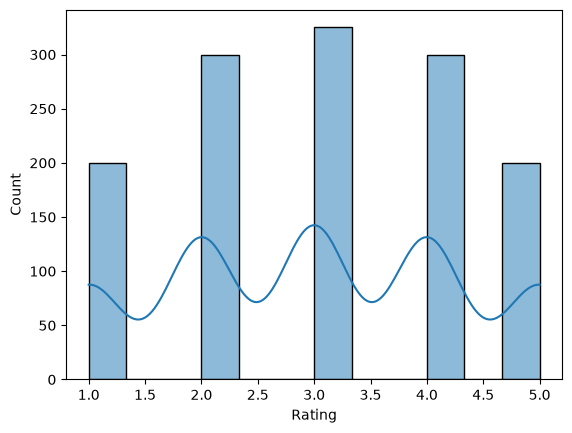

In [5]:
sns.histplot(data=df_resampled, x="Rating", kde=True)

In [6]:
df.describe()

,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,Rating
count,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000
mean,44.052104,1518.046092,3.062124,291.963928,3139.521042,3.430862
std,14.904828,672.212235,1.342145,120.482275,1224.609306,1.502585
min,18.000000,407.000000,1.000000,55.000000,536.000000,1.000000
25%,31.000000,951.500000,2.000000,185.000000,2000.000000,2.000000
50%,44.000000,1450.000000,3.000000,295.000000,3350.000000,4.000000
75%,58.000000,1995.000000,4.000000,400.000000,4100.000000,5.000000
max,96.000000,2997.000000,5.000000,498.000000,5250.000000,5.000000


In [7]:
df_resampled.describe()

,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,Rating
count,1325.000000,1325.000000,1325.000000,1325.000000,1325.000000,1325.000000
mean,44.060377,1524.086038,2.717736,314.218868,3203.642264,3.000000
std,13.786382,642.858885,1.229802,106.086127,1188.322780,1.289043
min,18.000000,407.000000,1.000000,55.000000,536.000000,1.000000
25%,32.000000,970.000000,2.000000,234.000000,2066.000000,2.000000
50%,43.000000,1500.000000,3.000000,327.000000,3405.000000,3.000000
75%,56.000000,1987.000000,4.000000,400.000000,4200.000000,4.000000
max,96.000000,2997.000000,5.000000,498.000000,5250.000000,5.000000


In [8]:
df.corr()[target].sort_values(ascending=False)

Rating                           1.000000
EnvironmentalAwareness           0.589104
HomeSize                         0.041610
Age                             -0.062691
MonthlyWaterConsumption         -0.557345
MonthlyElectricityConsumption   -0.571783
Name: Rating, dtype: float64

In [9]:
df_resampled.corr()[target].sort_values(ascending=False)

Rating                           1.000000
EnvironmentalAwareness           0.619850
HomeSize                         0.018746
Age                             -0.057503
MonthlyWaterConsumption         -0.410551
MonthlyElectricityConsumption   -0.554551
Name: Rating, dtype: float64

### even though we also tried to have 90% of synthetic data, the result were still surprisingly good